[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C12/E12-1_Suivi_Production_Parc_CORRIGE.ipynb)

# Suivi de production d'un parc de machines : ranger le temps et valider sans regarder l'avenir

## Le contexte

Cinq machines d'un même atelier sont suivies heure par heure pendant huit semaines. Le journal de supervision enregistre, pour chaque heure et chaque machine, la température de l'atelier, les minutes d'arrêt et le nombre de pièces produites. Quelques relevés manquent, à cause de coupures de liaison. Le journal arrive rangé par heure, toutes machines mélangées : avant d'y voir une série, il faut ranger le temps.

La production dépend de l'équipe (la nuit produit moins), du jour (la fin de semaine aussi) et des arrêts. Le planificateur voudrait connaître la production d'une machine quatre heures à l'avance, pour répartir les commandes de la demi-équipe suivante. La grandeur à prédire est un nombre de pièces par heure : c'est un problème de régression sur une série temporelle.

Défi : prédire `pieces_par_heure` quatre heures à l'avance et obtenir un R² supérieur à celui du modèle de départ sur la base de test. Le modèle de départ est une autorégression : une régression linéaire sur la production des trois dernières heures connues ; il atteint un R² de 0,581, alors que la persistance (répondre la dernière production connue) donne 0,523 et la production de la même heure une semaine plus tôt 0,790 : à vous de faire mieux. La base de test est formée des derniers 25 % du calendrier, soit les deux dernières semaines pour toutes les machines : jamais un tirage au hasard, car le futur ne doit pas passer dans l'apprentissage.

## Les données

Fichier `MecaIA-Suivi_Production_Parc.xlsx`, dans le dossier `donnees` du dépôt : environ 6 600 relevés, 5 colonnes. Une ligne est le relevé horaire d'une machine.

| Colonne | Signification | Unité |
|---|---|---|
| `horodatage` | heure pleine du relevé | date et heure |
| `machine` | identifiant de la machine, m1 à m5 | catégorie |
| `temperature_atelier_C` | température de l'air de l'atelier (quelques cases vides), sans effet sur la production | °C |
| `arret_min` | minutes d'arrêt dans l'heure, enregistrées en fin d'heure | min |
| `pieces_par_heure` | cible : pièces produites pendant l'heure | pièces/h |

Origine : jeu simulé, journal horaire de cinq machines avec une cadence de base propre à chaque machine, des effets d'équipe et de fin de semaine, une usure remise à zéro toutes les deux semaines, des arrêts aléatoires et environ 2 % de relevés perdus. Il enseigne une méthode, et aucune conclusion de procédé n'en découle.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on vérifie ses dimensions, ses cases vides, le nombre de relevés par machine et le nombre d'heures attendu. La forme d'un fichier se lit sur le fichier entier ; ce qui concerne la production elle-même sera regardé sur l'apprentissage seul. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-Suivi_Production_Parc.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-Suivi_Production_Parc.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

cible = "pieces_par_heure"
df["horodatage"] = pd.to_datetime(df["horodatage"])
vides = df.isna().sum()
print("dimensions :", df.shape)
print("cases vides par colonne :")
print(vides.to_string())
heures_attendues = int((df["horodatage"].max() - df["horodatage"].min()) / pd.Timedelta(hours=1)) + 1
releves = df["machine"].value_counts().sort_index()
print("heures attendues par machine :", heures_attendues)
print("relevés présents par machine :", releves.tolist())
print("du", df["horodatage"].min(), "au", df["horodatage"].max())
ordre_temps = bool(df["horodatage"].is_monotonic_increasing)
print("fichier rangé par heure croissante :", ordre_temps)

dimensions : (6592, 5)
cases vides par colonne :
horodatage                 0
machine                    0
temperature_atelier_C    189
arret_min                  0
pieces_par_heure           0
heures attendues par machine : 1344
relevés présents par machine : [1318, 1318, 1321, 1322, 1313]
du 2026-03-02 00:00:00 au 2026-04-26 23:00:00
fichier rangé par heure croissante : True


Lecture du résultat : 6 592 relevés pour 5 machines, sur 1344 heures attendues par machine, soit 6 720 relevés possibles : 128 relevés manquent, des lignes entières absentes et non des cases vides. Le fichier est rangé par heure croissante, toutes machines mélangées. Pour décaler une série d'une heure, un simple décalage de ligne serait faux dès qu'une heure manque : il faudra décaler par l'horodatage.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-Suivi_Production_Parc.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Étape 2 : ranger le temps et mettre le test de côté

On range les relevés par machine puis par heure. Le dernier quart du calendrier est mis de côté avant tout apprentissage et toute exploration de la production : il joue le rôle de l'avenir. La date de coupure est la date du relevé de rang n moins le quart des relevés, et tout relevé à partir de cette date va au test, de sorte qu'aucune heure n'ait des machines des deux côtés. Aucun mélange des lignes n'est permis.

In [2]:
import math

df = df.sort_values(["machine", "horodatage"])
coupure = df["horodatage"].sort_values(kind="stable").iloc[len(df) - math.ceil(0.25 * len(df))]
est_test = df["horodatage"] >= coupure
print("date de coupure :", coupure)
print("apprentissage :", int((~est_test).sum()), "relevés ; test :", int(est_test.sum()), "relevés")

date de coupure : 2026-04-13 00:00:00
apprentissage : 4944 relevés ; test : 1648 relevés


### Étape 3 : regarder la production d'apprentissage

Trois vues sur l'apprentissage seul : la production quotidienne de chaque machine (le total par jour, obtenu en regroupant les relevés par jour calendaire, c'est-à-dire en rééchantillonnant à la journée), la production moyenne selon l'heure de la journée et selon le jour de la semaine.

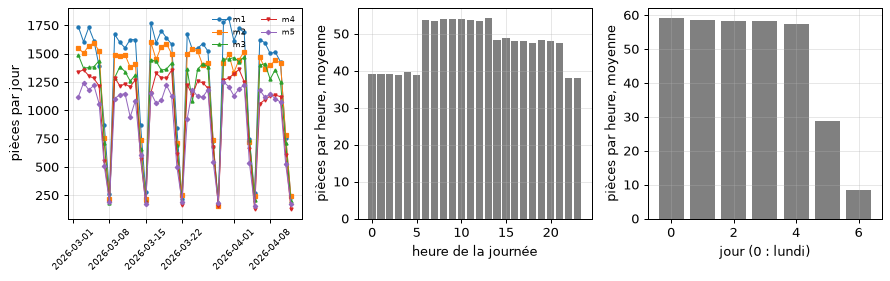

In [3]:
apprentissage = df[~est_test]
par_jour = apprentissage.groupby(["machine", pd.Grouper(key="horodatage", freq="D")])[cible].sum().unstack("machine")
par_heure = apprentissage.groupby(apprentissage["horodatage"].dt.hour)[cible].mean()
par_jour_semaine = apprentissage.groupby(apprentissage["horodatage"].dt.dayofweek)[cible].mean()

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for machine, marqueur in zip(par_jour.columns, ["o", "s", "^", "v", "D"]):
    axes[0].plot(par_jour.index, par_jour[machine], marker=marqueur, markersize=2.5, linewidth=0.8, label=machine)
axes[0].set_ylabel("pièces par jour")
axes[0].legend(frameon=False, fontsize=6, ncol=2)
axes[0].tick_params(axis="x", labelrotation=45, labelsize=7)
axes[1].bar(par_heure.index, par_heure.to_numpy(), color="0.5")
axes[1].set_xlabel("heure de la journée")
axes[1].set_ylabel("pièces par heure, moyenne")
axes[2].bar(par_jour_semaine.index, par_jour_semaine.to_numpy(), color="0.5")
axes[2].set_xlabel("jour (0 : lundi)")
axes[2].set_ylabel("pièces par heure, moyenne")
for axe in axes:
    axe.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Lecture du résultat : la production par jour oscille avec une période d'une semaine : elle chute à la fin de semaine, de 58,3 pièces par heure en moyenne du lundi au vendredi à 28,7 le samedi et 8,4 le dimanche. Dans la journée, la nuit (de 22 h à 6 h) produit moins que les deux autres équipes. Les cinq machines ont des niveaux différents mais le même rythme. Ces rythmes sont de l'information que la production des seules dernières heures ne porte pas.

### Étape 4 : construire les décalages

Pour prévoir la production d'une machine à l'heure t, on n'a le droit qu'aux relevés jusqu'à t moins quatre heures. On construit donc, pour chaque machine, la production décalée de 4, 5 et 6 heures. Le décalage se fait par l'horodatage, non par la ligne : si l'heure décalée manque dans le journal, la valeur est vide, et le modèle la remplacera par la médiane de l'apprentissage.

In [4]:
HORIZON = 4                                                      # heures


def decaler(colonne, heures):
    """Valeur de la colonne `heures` heures plus tôt, pour la même machine ; vide si ce relevé manque."""
    passe = df[["machine", "horodatage", colonne]].copy()
    passe["horodatage"] = passe["horodatage"] + pd.Timedelta(hours=heures)
    fusion = df[["machine", "horodatage"]].merge(passe, on=["machine", "horodatage"], how="left")
    return pd.Series(fusion[colonne].to_numpy(), index=df.index)


X_lags = pd.DataFrame({f"p_moins_{h}": decaler(cible, h) for h in range(HORIZON, HORIZON + 3)})
y = df[cible]
X_train, X_test = X_lags[~est_test], X_lags[est_test]
y_train, y_test = y[~est_test], y[est_test]
print(X_lags.head(3).to_string())
print("valeurs vides dans les décalages d'apprentissage :", int(X_train.isna().sum().sum()), "sur", X_train.size)

   p_moins_4  p_moins_5  p_moins_6
0        NaN        NaN        NaN
5        NaN        NaN        NaN
9        NaN        NaN        NaN
valeurs vides dans les décalages d'apprentissage : 354 sur 14832


### Étape 5 : construire le modèle de départ

Le modèle de départ est une autorégression : une régression linéaire qui prédit la production d'après celle des trois dernières heures connues. Le pipeline remplace d'abord les valeurs vides par la médiane de l'apprentissage, puis ajuste la droite. Il apprend sur `X_train` seul.

In [5]:
# Solution :
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

model = make_pipeline(SimpleImputer(strategy="median"), LinearRegression())
model.fit(X_train, y_train)
# Fin de la solution

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('linearregression', LinearRegression())])

### Étape 6 : mesurer sur la base de test

Le modèle prédit des heures qu'il n'a jamais vues. On lit le coefficient de détermination R² et deux erreurs en pièces par heure, la racine de l'erreur quadratique moyenne (RMSE) et l'erreur absolue moyenne (MAE). Trois témoins sans apprentissage servent de comparaison : la persistance, la production de la même heure sept jours plus tôt (la saison de la semaine) et la moyenne de l'apprentissage.

In [6]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

y_pred = model.predict(X_test)
score_depart = r2_score(y_test, y_pred)
semaine = decaler(cible, 168)
score_persistance = r2_score(y_test, X_test[f"p_moins_{HORIZON}"].fillna(y_train.mean()))
score_semaine = r2_score(y_test, semaine[est_test].fillna(y_train.mean()))
score_moyenne = r2_score(y_test, np.full(len(y_test), y_train.mean()))
print(f"R² : {score_depart:.3f}")
print(f"RMSE : {root_mean_squared_error(y_test, y_pred):.2f} pièces/h")
print(f"MAE : {mean_absolute_error(y_test, y_pred):.2f} pièces/h")
print(f"R² de la persistance : {score_persistance:.3f}")
print(f"R² de la même heure une semaine plus tôt : {score_semaine:.3f}")
print(f"R² de la moyenne de l'apprentissage : {score_moyenne:.3f}")

R² : 0.581
RMSE : 14.29 pièces/h
MAE : 10.16 pièces/h
R² de la persistance : 0.523
R² de la même heure une semaine plus tôt : 0.790
R² de la moyenne de l'apprentissage : -0.000


Lecture du résultat : le R² est de 0,581 et l'erreur absolue moyenne de 10,16 pièces par heure, pour une production moyenne de 46,6 sur la base de test. L'autorégression améliore la persistance (0,523), mais la production de la même heure une semaine plus tôt fait bien mieux (0,790) sans rien apprendre : elle porte à elle seule le rythme de l'équipe et de la fin de semaine. Les trois dernières heures ignorent ce rythme et se trompent aux changements d'équipe.

## Pour aller plus loin : le calendrier et la validation glissante

Le modèle de départ de l'étape 5 reste le score de référence du défi. Les deux cellules suivantes montrent comment le dépasser sans regarder le test pour choisir. La première compare des ensembles de variables par validation glissante sur l'apprentissage seul : la validation croisée habituelle mélangerait le temps, la validation glissante entraîne toujours sur le passé et valide sur le futur proche (`TimeSeriesSplit`, cinq découpages successifs, séparés par un écart de quatre heures). Elle essaie l'équipe et la fin de semaine, la production sept jours plus tôt, puis un gradient boosting qui reçoit aussi l'heure, le jour, la machine et les minutes d'arrêt de l'heure décalée. La seconde mesure le modèle retenu une seule fois sur le test. Les lectures sont imprimées par les cellules elles-mêmes.

In [7]:
# Solution :
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

heure = df["horodatage"].dt.hour
jour = df["horodatage"].dt.dayofweek
X_plus = X_lags.assign(
    nuit=((heure >= 22) | (heure < 6)).astype(int), apres_midi=((heure >= 14) & (heure < 22)).astype(int),
    samedi=(jour == 5).astype(int), dimanche=(jour == 6).astype(int),
    p_moins_168=semaine, heure=heure, jour=jour, machine=df["machine"].str[1].astype(int),
    arret_moins_4=decaler("arret_min", HORIZON))
calendrier = ["nuit", "apres_midi", "samedi", "dimanche"]
groupes = {
    "autorégression, trois décalages (modèle de départ)": list(X_lags.columns),
    "ajout de l'équipe et de la fin de semaine": list(X_lags.columns) + calendrier,
    "ajout de la production sept jours plus tôt": list(X_lags.columns) + calendrier + ["p_moins_168"],
    "gradient boosting, toutes les variables": list(X_plus.columns)}
candidats = {nom: make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True),
                                HistGradientBoostingRegressor(random_state=GRAINE) if "boosting" in nom else LinearRegression())
             for nom in groupes}
ordre = df.loc[X_train.index, "horodatage"].argsort(kind="stable")      # lignes d'apprentissage dans l'ordre du temps
X_ordre, y_ordre = X_plus.loc[X_train.index].iloc[ordre], y_train.iloc[ordre]
notes_cv = {}
for nom, colonnes in groupes.items():
    notes = cross_val_score(candidats[nom], X_ordre[colonnes], y_ordre, cv=TimeSeriesSplit(n_splits=5, gap=HORIZON * df["machine"].nunique()), scoring="r2")
    notes_cv[nom] = notes.mean()
    print(f"{nom} : R² {notes.mean():.3f} +/- {notes.std():.3f} sur 5 découpages glissants")
nom_retenu = max(notes_cv, key=notes_cv.get)
print("modèle retenu par la validation glissante :", nom_retenu)
# Fin de la solution

autorégression, trois décalages (modèle de départ) : R² 0.607 +/- 0.017 sur 5 découpages glissants
ajout de l'équipe et de la fin de semaine : R² 0.847 +/- 0.010 sur 5 découpages glissants
ajout de la production sept jours plus tôt : R² 0.858 +/- 0.012 sur 5 découpages glissants
gradient boosting, toutes les variables : R² 0.902 +/- 0.010 sur 5 découpages glissants
modèle retenu par la validation glissante : gradient boosting, toutes les variables


In [8]:
# Solution :
retenu = candidats[nom_retenu].fit(X_plus.loc[X_train.index, groupes[nom_retenu]], y_train)
r2_retenu = r2_score(y_test, retenu.predict(X_plus.loc[X_test.index, groupes[nom_retenu]]))
print(f"{nom_retenu}, mesuré une fois sur le test : R² {r2_retenu:.3f}")
print(f"gain sur le modèle de départ : {r2_retenu - score_depart:+.3f}")
# Fin de la solution

gradient boosting, toutes les variables, mesuré une fois sur le test : R² 0.892
gain sur le modèle de départ : +0.312


## Le score de référence

Le score publié est le R² du modèle de départ de l'étape 5 sur la base de test. L'empreinte identifie cette base de test : si la vôtre diffère, le découpage n'est pas le même et les scores ne se comparent pas.

In [9]:
import hashlib

score = r2_score(y_test, model.predict(X_test))
positions = ",".join(str(i) for i in sorted(X_test.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print("SCORE_REFERENCE r2 = %.3f" % score)

EMPREINTE_TEST = cd6f099248d44d3726aef3c08efaa073d98167d2820adcdd9e8d3d1d44fa9448
SCORE_REFERENCE r2 = 0.581


## Synthèse

1. Ranger le temps vient avant tout : trier par machine et par heure, vérifier les heures manquantes, décaler par l'horodatage et non par la ligne. Le test est la fin du calendrier, jamais un tirage au hasard.
2. Un modèle se compare à des témoins sans apprentissage : la persistance donne 0,523, la même heure une semaine plus tôt 0,790. Le modèle de départ, à 0,581, ne bat pas le second.
3. La validation glissante entraîne toujours sur le passé et valide sur l'avenir proche : sur l'apprentissage, l'équipe et la fin de semaine font passer le R² de 0,607 à 0,847.
4. Ajouter la production sept jours plus tôt porte la validation à 0,858 ; le gradient boosting avec toutes les variables atteint 0,902.
5. Le modèle retenu par la validation glissante est « gradient boosting, toutes les variables » ; mesuré une seule fois sur le test, il donne un R² de 0,892.